# Detecting IoT Network Attacks: Is the Model Reading Behaviour or Port Numbers?

**Question:** Can a machine learning model tell IoT attacks apart from normal device traffic using network-flow features, and how much of its accuracy comes from shortcuts in how the data was captured?

**Data:** the RT-IoT2022 dataset (UCI Machine Learning Repository). Each row is one network flow with 83 features (packet counts, timings, flags, payload sizes, ports) and one of 12 labels:
- **9 attack types:** DoS SYN flood, DDoS Slowloris, ARP poisoning, SSH brute force, and 5 kinds of NMAP scan
- **3 normal device patterns:** MQTT publishing, ThingSpeak, and a Wipro smart bulb

**What this notebook does:**
1. Cleans the data and checks for capture shortcuts
2. Tunes and compares 8 models (linear, distance-based, tree-based, ensembles, SVMs) with cross-validation
3. Repeats everything **with and without port features**, to test whether the models learned traffic behaviour or just port numbers
4. Looks at which attacks get missed, and which features matter

## 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RS = 42
NORMAL = {"MQTT_Publish", "Thing_Speak", "Wipro_bulb"}   # normal device traffic; everything else is an attack
PORT_FEATURES = ["id.orig_p", "id.resp_p", "service"]     # "service" is inferred from the port, so it goes too

# Chart styling
WITH_PORTS, NO_PORTS = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
})
IMG = "images"

## 2. Load and clean

In [2]:
df = pd.read_csv("data/rt_iot2022.csv.gz", na_values=["na"])
print(f"Loaded {len(df):,} flows x {df.shape[1]} columns")
print(f"Rows with no label:    {df['target'].isna().sum()}")
print(f"Missing feature cells: {df.drop(columns='target').isna().sum().sum()} (filled later by imputation)")

Loaded 123,117 flows x 84 columns
Rows with no label:    2
Missing feature cells: 298 (filled later by imputation)


Cleaning decisions:
- **Drop rows with no label.** You can't train or test on them, and keeping them would create a fake extra class.
- **Drop exact duplicate rows** before splitting, so the same flow can't appear in both training and test data.
- **Leave missing feature values for now.** They're filled inside the modelling pipeline, using statistics from the training data only.

In [3]:
df = df.dropna(subset=["target"])
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df):,} duplicate rows -> {len(df):,} flows\n")

counts = df["target"].value_counts().rename("flows").to_frame()
counts["share_%"] = (counts["flows"] / counts["flows"].sum() * 100).round(2)
counts["type"] = np.where(counts.index.isin(NORMAL), "normal", "attack")
counts

Removed 5,175 duplicate rows -> 117,940 flows



,flows,share_%,type
target,,,
DOS_SYN_Hping,90104,76.40,attack
Thing_Speak,7655,6.49,normal
ARP_poisioning,7627,6.47,attack
MQTT_Publish,4142,3.51,normal
NMAP_UDP_SCAN,2584,2.19,attack
NMAP_XMAS_TREE_SCAN,2010,1.70,attack
NMAP_OS_DETECTION,2000,1.70,attack
NMAP_TCP_scan,1002,0.85,attack
DDOS_Slowloris,533,0.45,attack


The classes are very unbalanced: one attack type (DoS SYN flood) is about three quarters of the data, while SSH brute force and FIN scans have only a few dozen flows each. A model could score over 75% accuracy by always guessing "DoS SYN flood", so **macro F1** (the average F1 across classes, weighting each class equally) is the main metric here, not accuracy.

### Checking for capture shortcuts

In a lab capture, each attack tool is often aimed at a fixed port. If that's the case here, a model can classify flows by port number alone, which won't work on real attackers who can use any port.

In [4]:
port_check = (df.groupby("target")["id.resp_p"]
              .agg(most_common_dest_port=lambda s: int(s.mode().iloc[0]),
                   share_using_it_pct=lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1),
                   flows="size")
              .sort_values("share_using_it_pct", ascending=False))
port_check

,most_common_dest_port,share_using_it_pct,flows
target,,,
DOS_SYN_Hping,21,100.0,90104
MQTT_Publish,1883,99.9,4142
DDOS_Slowloris,80,99.2,533
NMAP_FIN_SCAN,22,85.7,28
Metasploit_Brute_Force_SSH,22,77.8,36
Thing_Speak,53,49.5,7655
Wipro_bulb,443,45.2,219
ARP_poisioning,53,41.5,7627
NMAP_UDP_SCAN,80,5.6,2584


**Observations**
- **Three classes are tied to a single port:** every DoS SYN flood flow goes to port 21, 99.9% of MQTT traffic to port 1883, and 99.2% of Slowloris to port 80. Together these classes are about 80% of the data.
- SSH brute force (78%) and FIN scans (86%) mostly target port 22, while normal device traffic and the other scans are spread across many ports.
- So for the largest classes, the destination port alone almost gives away the label. That's a quirk of how the lab traffic was generated, not something that would hold for a real attacker. That's why every model below is trained twice: with all features, and with the port features (`id.orig_p`, `id.resp_p` and `service`, which is inferred from the port) removed.

## 3. Train/test split and pipelines

- **80/20 stratified split**, so every class (including the tiny ones) appears in the test set in proportion.
- **All preprocessing lives inside a pipeline** (median imputation and scaling for numbers, most-frequent imputation and one-hot encoding for categories). It's fitted on training data only, so nothing from the test set leaks into training.
- **Hyperparameters are tuned with 3-fold cross-validation on the training data**, scored on macro F1. The test set is used once, at the end, for the final scores.
- To keep tuning fast, cross-validation runs on a **tuning sample of up to 2,500 training flows per class**. This keeps every rare flow and trims the huge DoS class. The chosen settings are then refitted on the **full** training set. The exception is the RBF SVM, which stays on the tuning sample because kernel SVM training time grows roughly with the square of the number of rows.

In [5]:
le = LabelEncoder()
y = le.fit_transform(df["target"])
X = df.drop(columns="target")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

rng = np.random.default_rng(RS)
tune_idx = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(y_train == c), size=min((y_train == c).sum(), 2500), replace=False)
    for c in np.unique(y_train)
]))
X_tune, y_tune = X_train.iloc[tune_idx], y_train[tune_idx]

print(f"Train: {len(X_train):,}   Test: {len(X_test):,}   Tuning sample: {len(X_tune):,}")

FEATURE_SETS = {
    "All features": list(X.columns),
    "No port features": [c for c in X.columns if c not in PORT_FEATURES],
}

def make_preprocessor(cols):
    cat = [c for c in cols if not pd.api.types.is_numeric_dtype(X[c])]
    num = [c for c in cols if c not in cat]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ], sparse_threshold=0)

Train: 94,352   Test: 23,588   Tuning sample: 16,729


## 4. Models

| Model | Why it's here |
|---|---|
| Logistic Regression | Simple, interpretable linear baseline |
| KNN | Distance-based; tests whether similar flows share labels |
| Decision Tree | Handles non-linear rules and mixed features; easy to explain |
| Random Forest | Bagged trees; usually more robust than a single tree |
| XGBoost | Boosted trees; often the strongest on tabular data |
| Voting (soft) | Averages the probabilities of three *different* learners (LR + KNN + Tree) |
| Linear SVM | Multiclass via **one-vs-rest**: one boundary per class |
| RBF SVM | Multiclass via **one-vs-one**: one boundary per pair of classes (66 for 12 classes) |

In [6]:
MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=3000), {"clf__C": [0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(n_jobs=-1), {"clf__n_neighbors": [3, 7, 15], "clf__weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RS), {"clf__max_depth": [10, 20, None], "clf__min_samples_leaf": [1, 5]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RS),
                      {"clf__max_depth": [20, None], "clf__min_samples_leaf": [1, 2]}),
    "XGBoost": (XGBClassifier(n_estimators=200, tree_method="hist", n_jobs=-1, random_state=RS, eval_metric="mlogloss"),
                {"clf__max_depth": [4, 8], "clf__learning_rate": [0.1, 0.3]}),
    "Linear SVM (one-vs-rest)": (LinearSVC(dual=False, max_iter=5000), {"clf__C": [0.1, 1, 10]}),
    "RBF SVM (one-vs-one)": (SVC(kernel="rbf", gamma="scale"), {"clf__C": [1, 10]}),
}
PARALLEL_INSIDE = {"KNN", "Random Forest", "XGBoost"}   # these already use all cores
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)

results, fitted = [], {}

def evaluate(fs_name, name, model, params, cv_f1, X_fit, y_fit):
    t0 = time.perf_counter(); model.fit(X_fit, y_fit); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(X_test); pred_s = time.perf_counter() - t0
    results.append({
        "features": fs_name, "model": name, "best_params": params, "cv_macro_f1": cv_f1,
        "test_accuracy": accuracy_score(y_test, pred),
        "test_macro_f1": f1_score(y_test, pred, average="macro"),
        "test_macro_recall": recall_score(y_test, pred, average="macro"),
        "fit_seconds": fit_s, "predict_seconds": pred_s,
    })
    fitted[(fs_name, name)] = (model, pred)
    print(f"{fs_name:17} | {name:26} | macro F1 {results[-1]['test_macro_f1']:.3f} | accuracy {results[-1]['test_accuracy']:.4f}")

for fs_name, cols in FEATURE_SETS.items():
    for name, (est, grid) in MODELS.items():
        pipe = Pipeline([("prep", make_preprocessor(cols)), ("clf", est)])
        search = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro",
                              n_jobs=1 if name in PARALLEL_INSIDE else -1)
        search.fit(X_tune, y_tune)
        params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
        X_fit, y_fit = (X_tune, y_tune) if name.startswith("RBF") else (X_train, y_train)
        evaluate(fs_name, name, clone(search.best_estimator_), params, search.best_score_, X_fit, y_fit)

    # Soft voting over three different kinds of learner, each with its tuned settings
    voters = [(short, clone(fitted[(fs_name, full)][0].named_steps["clf"]))
              for short, full in [("lr", "Logistic Regression"), ("knn", "KNN"), ("tree", "Decision Tree")]]
    vote = Pipeline([("prep", make_preprocessor(cols)), ("clf", VotingClassifier(voters, voting="soft"))])
    evaluate(fs_name, "Voting (LR + KNN + Tree)", vote, "tuned members", np.nan, X_train, y_train)

All features      | Logistic Regression        | macro F1 0.958 | accuracy 0.9932


All features      | KNN                        | macro F1 0.974 | accuracy 0.9963


All features      | Decision Tree              | macro F1 0.969 | accuracy 0.9975


All features      | Random Forest              | macro F1 0.995 | accuracy 0.9984


All features      | XGBoost                    | macro F1 0.994 | accuracy 0.9984


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


... (7 outputs left out)

No port features  | XGBoost                    | macro F1 0.985 | accuracy 0.9957


No port features  | Linear SVM (one-vs-rest)   | macro F1 0.936 | accuracy 0.9810


No port features  | RBF SVM (one-vs-one)       | macro F1 0.934 | accuracy 0.9863


No port features  | Voting (LR + KNN + Tree)   | macro F1 0.965 | accuracy 0.9913


## 5. Results

In [7]:
res = pd.DataFrame(results)
table = (res.pivot(index="model", columns="features", values="test_macro_f1")
         .assign(drop_without_ports=lambda t: t["All features"] - t["No port features"])
         .sort_values("No port features", ascending=False))
table.round(3)

features,All features,No port features,drop_without_ports
model,,,
XGBoost,0.994,0.985,0.009
Random Forest,0.995,0.984,0.011
Voting (LR + KNN + Tree),0.993,0.965,0.028
KNN,0.974,0.949,0.024
Decision Tree,0.969,0.941,0.028
Linear SVM (one-vs-rest),0.964,0.936,0.028
RBF SVM (one-vs-one),0.970,0.934,0.036
Logistic Regression,0.958,0.919,0.038


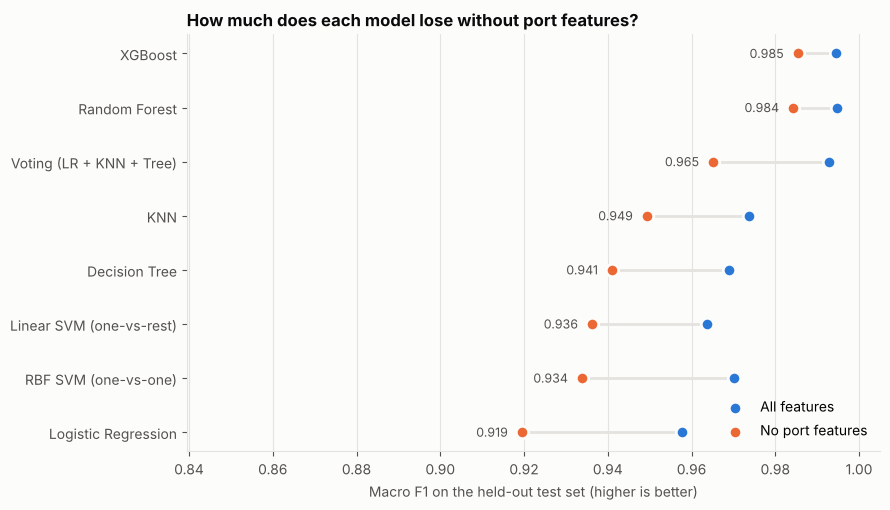

In [8]:
order = table.index[::-1]                      # best (no ports) at the top
fig, ax = plt.subplots(figsize=(9, 5.2))
ypos = np.arange(len(order))
w = table.loc[order, "All features"].values
n = table.loc[order, "No port features"].values

ax.hlines(ypos, n, w, color=GRID, linewidth=2, zorder=1)
ax.scatter(w, ypos, s=80, color=WITH_PORTS, edgecolor="#fcfcfb", linewidth=2, zorder=3, label="All features")
ax.scatter(n, ypos, s=80, color=NO_PORTS, edgecolor="#fcfcfb", linewidth=2, zorder=3, label="No port features")
for yi, val in zip(ypos, n):
    ax.annotate(f"{val:.3f}", (val, yi), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", color=INK2, fontsize=9)

ax.set_yticks(ypos, order)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Macro F1 on the held-out test set (higher is better)")
ax.set_title("How much does each model lose without port features?", loc="left")
ax.legend(loc="lower right", frameon=False)
lo = min(n.min(), w.min())
ax.set_xlim(lo - 0.08, 1.005)
plt.tight_layout()
plt.savefig(f"{IMG}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
cols_show = ["features", "model", "best_params", "cv_macro_f1", "test_accuracy", "test_macro_f1", "fit_seconds", "predict_seconds"]
res[cols_show].sort_values(["features", "test_macro_f1"], ascending=[True, False]).round(4)

,features,model,best_params,cv_macro_f1,test_accuracy,test_macro_f1,fit_seconds,predict_seconds
3,All features,Random Forest,"{'max_depth': 20, 'min_samples_leaf': 1}",0.9618,0.9984,0.9948,6.2989,0.1854
4,All features,XGBoost,"{'learning_rate': 0.3, 'max_depth': 8}",0.9642,0.9984,0.9944,24.2292,0.3164
7,All features,Voting (LR + KNN + Tree),tuned members,NaN,0.9974,0.9928,37.9718,6.8306
1,All features,KNN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.9439,0.9963,0.9736,0.9227,6.5849
6,All features,RBF SVM (one-vs-one),{'C': 10},0.9366,0.9949,0.9702,1.3960,3.8039
2,All features,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 1}",0.9492,0.9975,0.9688,1.5421,0.0528
5,All features,Linear SVM (one-vs-rest),{'C': 1},0.9308,0.9899,0.9637,714.6656,0.0508
0,All features,Logistic Regression,{'C': 10},0.9305,0.9932,0.9578,42.8931,0.0875
12,No port features,XGBoost,"{'learning_rate': 0.1, 'max_depth': 4}",0.9487,0.9957,0.9853,22.2529,0.2919
11,No port features,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.9483,0.9958,0.9842,5.8222,0.1743


**Observations**
- **The tree ensembles learned real traffic behaviour.** Without port features, XGBoost only drops from 0.994 to 0.985 macro F1, and Random Forest from 0.995 to 0.984.
- **The simpler models leaned on ports more.** Logistic Regression drops from 0.958 to 0.919, and the RBF SVM from 0.970 to 0.934.
- **Accuracy hides the differences.** Every model scores above 98% accuracy even without ports, because three quarters of the test set is one easy class. Macro F1 ranges from 0.919 to 0.985, which shows how differently the models handle the smaller classes.
- **Combining different learners helps, but trees still win.** Soft voting (0.965 without ports) beats each of its own members (Logistic Regression 0.919, KNN 0.949, Decision Tree 0.941), but bagged and boosted trees are better still.
- **SVMs don't scale well here.** The one-vs-rest Linear SVM was by far the slowest model to train (about 12 minutes with ports and 18 without, against 6 seconds for Random Forest), and still hit its iteration limit, as the convergence warnings above show. The one-vs-one RBF SVM was only trainable on the 16.7k-row tuning sample, and it still scored below the tree models.
- **Cross-validation scores are lower than test scores** (e.g. XGBoost 0.949 vs 0.985). That's expected: the class-capped tuning sample makes the rare, harder classes a much bigger share of each fold. It isn't a sign of overfitting.

## 6. Which attacks get missed?

For a security team, the costly mistake is an **attack classified as normal traffic**, because nobody investigates it. A false alarm on normal traffic is annoying but cheaper. This table collapses the 12 classes into attack vs normal for the models trained **without** port features.

In [10]:
is_normal = np.isin(le.classes_, list(NORMAL))
true_attack = ~is_normal[y_test]

rows = []
for (fs_name, name), (_, pred) in fitted.items():
    pred_attack = ~is_normal[pred]
    rows.append({"features": fs_name, "model": name,
                 "missed_attacks": int((true_attack & ~pred_attack).sum()),
                 "false_alarms": int((~true_attack & pred_attack).sum())})
binary = pd.DataFrame(rows)
print(f"Test set: {true_attack.sum():,} attack flows, {(~true_attack).sum():,} normal flows\n")
binary[binary["features"] == "No port features"].sort_values("missed_attacks").reset_index(drop=True)

Test set: 21,185 attack flows, 2,403 normal flows



,features,model,missed_attacks,false_alarms
0,No port features,Voting (LR + KNN + Tree),13,32
1,No port features,Random Forest,17,16
2,No port features,XGBoost,17,19
3,No port features,Decision Tree,17,39
4,No port features,KNN,26,48
5,No port features,RBF SVM (one-vs-one),35,78
6,No port features,Logistic Regression,98,49
7,No port features,Linear SVM (one-vs-rest),159,68


In [11]:
best_name = table.index[0]                      # best macro F1 without ports
best_model, best_pred = fitted[("No port features", best_name)]
print(f"Best model without port features: {best_name}\n")
print(classification_report(y_test, best_pred, target_names=le.classes_, digits=3))

Best model without port features: XGBoost

                            precision    recall  f1-score   support

            ARP_poisioning      0.985     0.958     0.971      1525
            DDOS_Slowloris      0.953     0.953     0.953       107
             DOS_SYN_Hping      1.000     1.000     1.000     18021
              MQTT_Publish      1.000     0.999     0.999       828
Metasploit_Brute_Force_SSH      1.000     1.000     1.000         7
             NMAP_FIN_SCAN      1.000     1.000     1.000         6
         NMAP_OS_DETECTION      1.000     1.000     1.000       400
             NMAP_TCP_scan      0.990     1.000     0.995       200
             NMAP_UDP_SCAN      0.907     0.981     0.942       517
       NMAP_XMAS_TREE_SCAN      1.000     0.998     0.999       402
               Thing_Speak      0.987     0.988     0.987      1531
                Wipro_bulb      1.000     0.955     0.977        44

                  accuracy                          0.996     23588
   

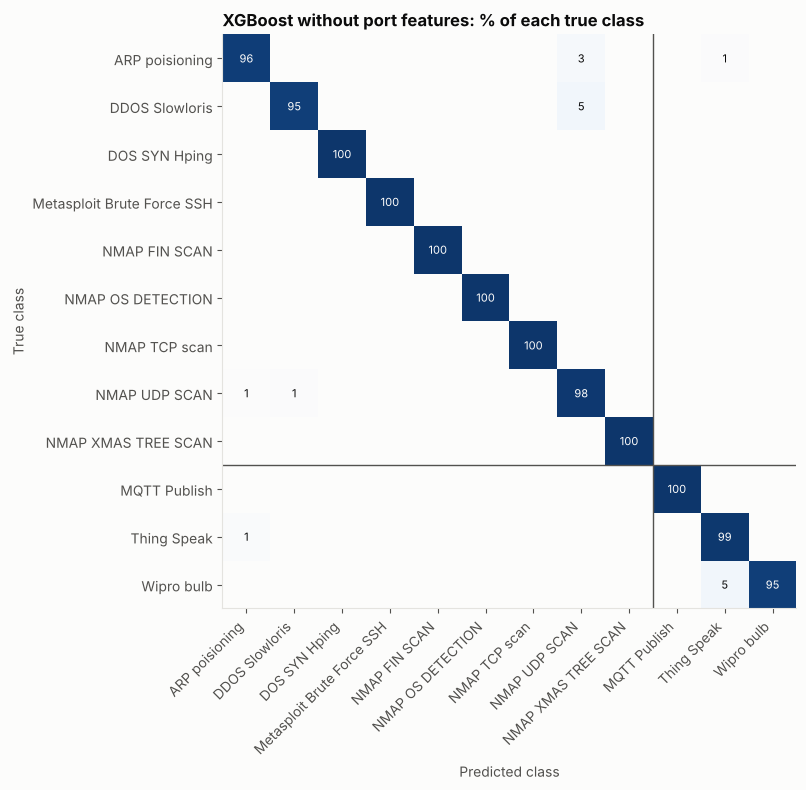

In [12]:
attacks_first = [c for c in le.classes_ if c not in NORMAL] + sorted(NORMAL)
idx = [list(le.classes_).index(c) for c in attacks_first]
cm = confusion_matrix(y_test, best_pred, labels=idx, normalize="true")

blues = LinearSegmentedColormap.from_list("blue_ramp", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(9.5, 8))
ax.imshow(cm, cmap=blues, vmin=0, vmax=1)
labels = [c.replace("_", " ") for c in attacks_first]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = cm[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v*100:.0f}", ha="center", va="center", fontsize=8,
                    color="#fcfcfb" if v > 0.55 else INK)
n_attacks = len(attacks_first) - len(NORMAL)
ax.axhline(n_attacks - 0.5, color=INK2, linewidth=1)
ax.axvline(n_attacks - 0.5, color=INK2, linewidth=1)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"{best_name} without port features: % of each true class", loc="left")
plt.tight_layout()
plt.savefig(f"{IMG}/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **The best models miss very few attacks without port features:** soft voting misses 13, and Random Forest and XGBoost 17 each, out of 21,185 attack flows (under 0.1%).
- **Linear models miss far more:** Logistic Regression misses 98 attacks, and the Linear SVM 159.
- **There's a trade-off:** voting misses the fewest attacks but raises 32 false alarms, double Random Forest's 16.
- **XGBoost's mistakes are concentrated in a few places:** 3% of ARP poisoning flows and 5% of Slowloris flows are mistaken for UDP scans (still flagged as attacks, just the wrong type). 5% of Wipro bulb traffic is labelled as ThingSpeak, which is normal mistaken for normal and harmless. About 1% of ThingSpeak traffic is flagged as ARP poisoning, which is a false alarm.
- The rare SSH brute force (7 test flows) and FIN scan (6) classes are all classified correctly, but there are too few of them to be confident about that.

## 7. Which features matter?

**Permutation importance** shuffles one feature at a time and measures how much macro F1 drops. Unlike a tree's built-in importance, it works for any model and is measured on unseen data, so it reflects what the model actually relies on at prediction time.

It's run for the same model type twice: once trained **with** ports and once **without**, on a stratified sample of 6,000 test flows to keep it fast.

In [13]:
imp_name = table.loc[["Random Forest", "XGBoost"], "No port features"].idxmax()
_, X_imp, _, y_imp = train_test_split(X_test, y_test, test_size=6000, stratify=y_test, random_state=RS)

importances = {}
for fs_name, cols in FEATURE_SETS.items():
    model = fitted[(fs_name, imp_name)][0]
    r = permutation_importance(model, X_imp[cols], y_imp, scoring="f1_macro", n_repeats=5, random_state=RS, n_jobs=-1)
    importances[fs_name] = pd.Series(r.importances_mean, index=cols).sort_values(ascending=False)

pd.DataFrame({k: v.head(10).index for k, v in importances.items()})

,All features,No port features
0,fwd_URG_flag_count,fwd_pkts_payload.min
1,fwd_last_window_size,fwd_last_window_size
2,service,fwd_URG_flag_count
3,fwd_header_size_min,fwd_header_size_min
4,flow_FIN_flag_count,flow_FIN_flag_count
5,flow_iat.min,bwd_iat.min
6,id.resp_p,flow_iat.min
7,bwd_init_window_size,fwd_pkts_per_sec
8,fwd_pkts_per_sec,flow_pkts_payload.max
9,flow_pkts_per_sec,fwd_pkts_payload.avg


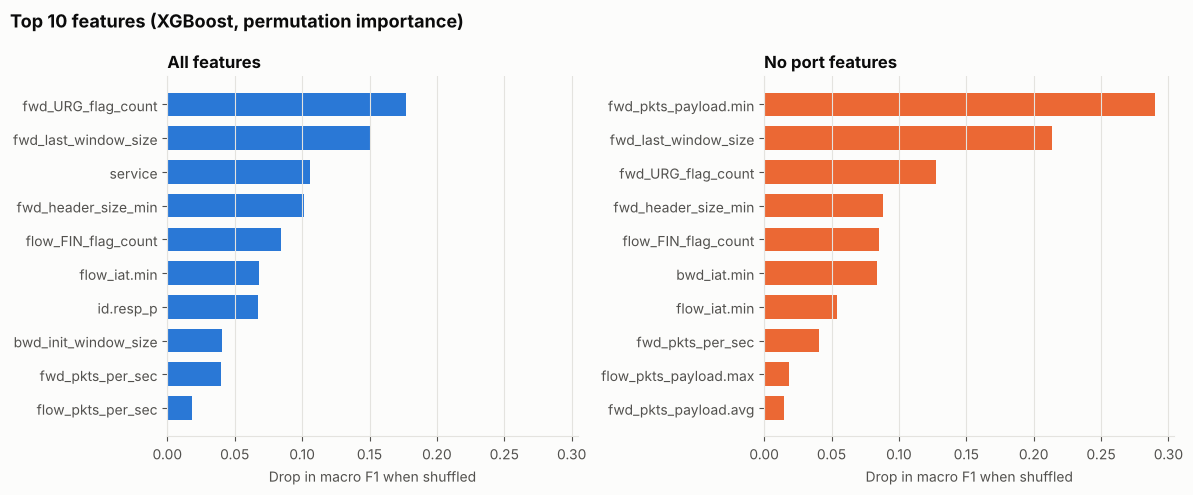

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (fs_name, colour) in zip(axes, [("All features", WITH_PORTS), ("No port features", NO_PORTS)]):
    top = importances[fs_name].head(10)[::-1]
    ax.barh(top.index, top.values, color=colour, height=0.7)
    ax.set_title(fs_name, loc="left")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Drop in macro F1 when shuffled")
fig.suptitle(f"Top 10 features ({imp_name}, permutation importance)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{IMG}/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **With ports available, the model does use them:** `service` is the 3rd most important feature and `id.resp_p` the 7th. They aren't its main signal, though, which is why removing them costs so little.
- **Without ports, the top features describe how the traffic behaves:** the smallest forward payload, TCP window sizes, URG and FIN flag counts, header sizes and packet timing.
- **These match how the attacks actually work.** XMAS tree scans send packets with the FIN, PSH and URG flags set, FIN scans send FIN packets, and SYN floods send many packets with no payload. So the model is picking up genuine attack signatures.
- **For deployment,** these are the features to monitor for drift. If a network's normal traffic changes its payload sizes or window sizes, the model should be re-checked.

## 8. Recommendation

**Recommended model: Random Forest trained without port features.**

| Consideration | Random Forest (no ports) |
|---|---|
| Detection | Macro F1 0.984; misses 17 of 21,185 attacks with 16 false alarms |
| Robustness | Doesn't depend on port numbers, which attackers can change |
| Speed | About 6 s to train on 94k flows; under 0.2 s to score 23.6k flows |
| Maintainability | Few hyperparameters, no scaling needed, simple to retrain |
| Interpretability | Less transparent than a single tree, but permutation importance and per-class reports explain its behaviour |

XGBoost performs almost identically (0.985) but takes about 4 times longer to train and has more settings to tune, so Random Forest is the simpler choice to maintain. If missing an attack is much more costly than a false alarm, the soft-voting ensemble misses the fewest attacks (13), at the cost of twice as many false alarms and much slower predictions. If a fully explainable model is required, a depth-10 decision tree (0.941) is a readable fallback.

## 9. Limitations
- **One lab capture.** All traffic comes from a single testbed, so even the no-port models may have learned other quirks of that environment (e.g. typical packet sizes of one attack tool). Testing on traffic from a different network would be the real check.
- **Very rare classes.** SSH brute force and FIN scans have only a handful of test flows, so their scores can swing a lot from one or two predictions.
- **Tuning on a capped sample.** Hyperparameters were chosen on a class-capped tuning sample for speed. Tuning on the full training set might shift settings slightly.
- **The RBF SVM was trained on the tuning sample only**, so it saw less data than the other models.